# Qafila Lakehouse · Capstone demo

**Team:** Yahya Mohammed Khuzaimi · Abdullah Bin Ghafrah · **Course:** Modern Data Engineering, SDAIA Academy

Choose **Runtime → Run all**. The first run takes a few minutes to install the tools. All data is synthetic.

## 1 · Set up

In [1]:
import os, shutil, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/vxji/data-engineering.git"
COURSE_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
ROOT = Path("/content/data-engineering")
ZIP = Path("/content/qafila-lakehouse-upload.zip")    # optional: upload it to Colab's Files panel


def clone(url):
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}
    return subprocess.run(["git", "clone", "-q", url, str(ROOT)], env=env).returncode == 0


if "google.colab" in sys.modules:
    if not (ROOT / "labs/capstone/ingest/incremental.py").exists():
        shutil.rmtree(ROOT, ignore_errors=True)
        if not clone(REPO_URL):
            print("Your repository isn't reachable, so using the course repository plus the uploaded zip.")
            shutil.rmtree(ROOT, ignore_errors=True)
            if not clone(COURSE_URL):
                raise RuntimeError("Could not clone the course repository. Check the runtime's internet access.")
        if ZIP.exists():
            shutil.unpack_archive(ZIP, ROOT)
        if not (ROOT / "labs/capstone/ingest/incremental.py").exists():
            raise FileNotFoundError("Project files not found. Upload qafila-lakehouse-upload.zip to /content, or publish them to your public fork.")
    os.chdir(ROOT / "labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")
print("working in", os.getcwd())

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

import de_utils as U

U.ensure_data()
HOME = U.ARTIFACTS / "capstone"
DB, VAULT = HOME / "qafila.duckdb", HOME / "vault.duckdb"


def q(sql, path=DB):
    con = duckdb.connect(str(path), read_only=True)
    try:
        con.execute("SET enable_progress_bar = false")     # needs ipywidgets in a notebook
    except duckdb.Error:
        pass
    try:
        return con.execute(sql).df()
    finally:
        con.close()

working in /tmp/data-engineering/labs


## 2 · One command, end to end

Sources → raw → staging → marts → role views → Iceberg gold. Three warnings are expected, and each has an owner.

In [2]:
!python capstone/pipeline.py --reset 2>&1 | grep -E '^(run |  WARN|  ERROR)'

run succeeded: 35 assets built, 55 of 58 checks passed
  WARN    staging/stg_order_items · positive_stg_order_items_quantity: 142 failing rows
  WARN    staging/stg_supplier_prices · positive_stg_supplier_prices_unit_cost_sar: 4 failing rows
  WARN    marts/fct_orders · assert_order_totals_match_payments: 244 failing rows


## 3 · A re-run changes nothing

We replay the platform on 27 September, run it again, then move two days forward. The script compares a hash of every row.

In [3]:
!python capstone/prove_rerun.py

1. First load


  as of 2026-09-27: run succeeded: 35 assets built, 55 of 58 checks passed


2. The scheduler runs it again, same day


  as of 2026-09-27: run succeeded: 35 assets built, 55 of 58 checks passed


3. Two days later: new payments, refunds of old ones, new events


  as of 2026-09-29: run succeeded: 35 assets built, 55 of 58 checks passed



                             first run  re-run  2 days later  re-run identical
table                                                                         
raw.payments                     38999   38999         40402              True
raw.delivery_events              10465   10465         16504              True
staging.stg_payments             38984   38984         40386              True
quarantine.qrn_payments             15      15            16              True
marts.fct_order_items           172403  172403        172403              True
marts.fct_orders                 45766   45766         45766              True
marts.mart_daily_city_sales        183     183           183              True
marts.mart_ops_daily                12      12            18              True

     as_of          source  fetched   new  updated  unchanged
2026-09-27 delivery_events    10465 10465        0          0
2026-09-27        payments    38999 38999        0          0
2026-09-27 delivery_ev

## 4 · A bad feed stops the run

The provider sends a status nobody agreed. The contract blocks, so the marts keep their last good numbers.

In [4]:
!python capstone/prove_rerun.py --block

1. A good run


  as of 2026-09-27: run succeeded: 35 assets built, 55 of 58 checks passed


2. The provider starts sending a status nobody agreed: refund_pending


  as of 2026-09-29: run STOPPED: 9 assets built, 2 of 3 checks passed | ERROR   raw/payments · payments_contract: status: 1 (mustBe 0)



                             before  after the bad feed
table                                                  
raw.payments                  38999               40402
raw.delivery_events           10465               16504
staging.stg_payments          38984               40386
quarantine.qrn_payments          15                  15
marts.fct_order_items        172403              172403
marts.fct_orders              45766               45766
marts.mart_daily_city_sales     183                 183
marts.mart_ops_daily             12                  12

PASS: the run stopped, and the marts kept yesterday's numbers


## 5 · Bad rows go to quarantine, with an owner

Each row keeps its reason, and someone owns the list.

In [5]:
q("""
    SELECT 'payments' AS source, reject_reason, owner, count(*) AS rows FROM quarantine.qrn_payments GROUP BY ALL
    UNION ALL SELECT 'order lines', reject_reason, owner, count(*) FROM quarantine.qrn_order_items GROUP BY ALL
    UNION ALL SELECT 'supplier prices', reject_reason, owner, count(*) FROM quarantine.qrn_supplier_prices GROUP BY ALL
    ORDER BY rows DESC
""")

,source,reject_reason,owner,rows
0,order lines,non-positive quantity,finance-operations,142
1,payments,non-positive amount,payments-provider-integration,16
2,supplier prices,non-positive cost,purchasing,4
3,supplier prices,unknown SKU,purchasing,3


## 6 · Personal data stays out

Identifiers live in a separate vault file. The warehouse holds keyed tokens, and analysts read views. This cell shows the structure only, so no customer data appears in the notebook.

In [6]:
from importlib import import_module

sys.path.insert(0, "capstone")
privacy = import_module("governance.privacy")

raw_columns = q("SELECT column_name FROM information_schema.columns WHERE table_schema = 'raw' AND table_name = 'customers'").column_name.tolist()
analyst_columns = q("SELECT column_name FROM information_schema.columns WHERE table_schema = 'analyst' AND table_name = 'customers'").column_name.tolist()
print("raw.customers    :", raw_columns)
print("analyst.customers:", analyst_columns)
print("PII found by scanning values:", privacy.scan(DB, ["raw", "staging", "intermediate", "marts", "quarantine", "analyst"]) or "none")
q("SELECT location, \"column\", pii, level, protection FROM ops.data_catalog")

raw.customers    : ['customer_id', 'person_token', 'email_domain', 'city', 'district', 'created_at', 'updated_at', 'is_deleted', '_loaded_at']
analyst.customers: ['customer_id', 'is_duplicate_account', 'city', 'signup_date']


PII found by scanning values: none


,location,column,pii,level,protection
0,vault.customers_pii,national_id,national ID,Secret,Vault only; token in the warehouse
1,vault.customers_pii,iban,bank account,Secret,Vault only; never leaves it
2,vault.customers_pii,full_name,name,Restricted,Vault only; support view
3,vault.customers_pii,email,email,Restricted,Vault only; domain in the warehouse
4,vault.customers_pii,mobile,mobile,Restricted,Vault only; masked in the support view
5,raw.customers,person_token,pseudonym,Restricted,HMAC-SHA256 with a key outside git
6,raw.customers,email_domain,indirect,Restricted,Domain only; left out of analyst views
7,raw.customers,city,indirect,Restricted,Personal by association
8,raw.customers,district,indirect,Restricted,Left out of analyst views
9,raw.payments,card_last4,partial card number,Restricted,Stops at staging; not in marts


## 7 · What the business gets

,product_revenue_sar,delivered_orders
0,6500179.0,40419


,city,delivered,breaches,missed_sla_pct
0,Riyadh,2642.0,1120.0,42.4
1,Jeddah,1686.0,476.0,28.2
2,Dammam,929.0,252.0,27.1


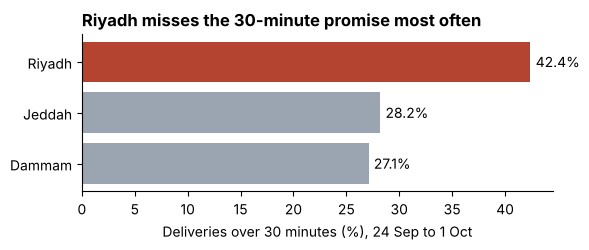

In [7]:
revenue = q("""SELECT round(sum(items_amount)) AS product_revenue_sar, count(*) AS delivered_orders
               FROM analyst.orders WHERE status = 'delivered'""")
ops = q("""SELECT city, sum(delivered_orders) AS delivered, sum(sla_breaches) AS breaches,
                   round(100.0 * sum(sla_breaches) / sum(delivered_orders), 1) AS missed_sla_pct
            FROM analyst.ops_daily GROUP BY city ORDER BY missed_sla_pct DESC""")
display(revenue, ops)

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(ops.city[::-1], ops.missed_sla_pct[::-1], color=["#9aa5b1"] * (len(ops) - 1) + ["#b4432f"])
ax.set_title("Riyadh misses the 30-minute promise most often", loc="left", fontweight="bold")
ax.set_xlabel("Deliveries over 30 minutes (%), 24 Sep to 1 Oct")
ax.spines[["top", "right"]].set_visible(False)
for i, v in enumerate(ops.missed_sla_pct[::-1]):
    ax.text(v + 0.5, i, f"{v}%", va="center")
plt.tight_layout()
plt.show()

## 8 · What the platform recorded

Every load logs what it fetched, added and changed.

In [8]:
q("""SELECT source, rows_fetched, rows_new, rows_updated, rows_unchanged, requests, throttled, cursor_after
     FROM ops.ingest_log ORDER BY logged_at""")

,source,rows_fetched,rows_new,rows_updated,rows_unchanged,requests,throttled,cursor_after
0,delivery_events,22518,22518,0,0,0,0,2026-10-01 00:19:26.864+03
1,payments,41785,41785,0,0,87,3,2026-09-30T23:59:59.000Z
